In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("Carseats.csv")

df.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,Unnamed: 11
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes,NaN
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes,NaN
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes,NaN
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes,NaN
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No,NaN


In [3]:
df = df.dropna(axis=1, how="all")

X = pd.get_dummies(df.drop("Sales", axis=1), drop_first=True)
y = df["Sales"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [6]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
209,3.02,6.3797
280,2.86,4.9430
33,8.77,10.3846
210,4.36,5.7379
93,8.86,7.8897
84,2.23,5.1272
329,11.27,11.0076
94,8.39,7.1517
266,9.10,10.2122
126,11.27,10.1116


In [7]:
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 3.0241342891249996
R2 Score: 0.6944146712943908


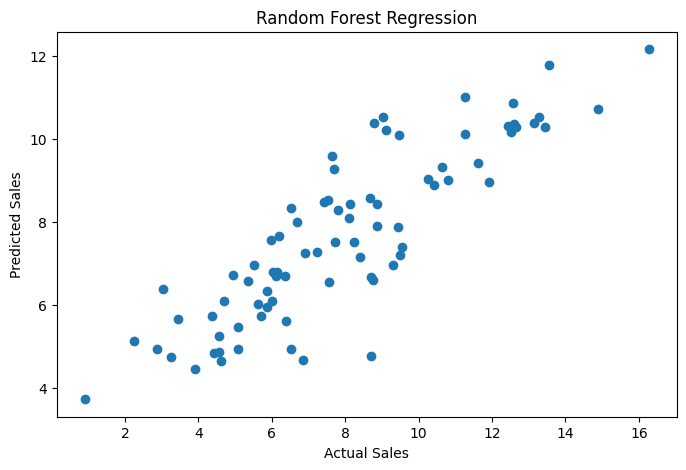

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest Regression")

plt.show()

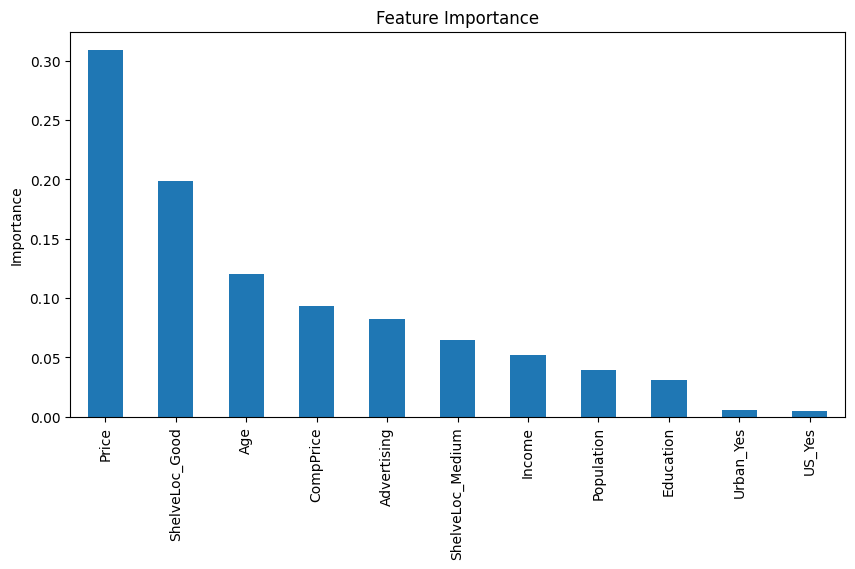

In [9]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.plot(kind="bar", figsize=(10, 5))

plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()